# Γραμμικός Προγραμματισμός

### Βοηθητικές βιβλιοθήκες για την υλοποίηση και παρουσίαση των αλγορίθμων

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

## 1. Υλοποίηση και επίλυση του προβλήματος

In [3]:
# linprog performs minimization, so we minimize -z = -3x1 + 10x2
c = [-3, 10]

# Constraints A_ub * x <= b_ub
A = [
    [-2, 1],      # -2x1 + x2 <= 12
    [-1, 3],      # -x1 + 3x2 <= 3
    [6, 7],       # 6x1 + 7x2 <= 18
    [3, -12],     # -3x1 + 12x2 >= 8 -> 3x1 - 12x2 <= -8
    [2, -7],      # 2x1 - 7x2 <= 35
    [-1, 8],      # -x1 + 8x2 <= 29
    [2, -6]       # 2x1 - 6x2 <= 9
]

b = [12, 3, 18, -8, 35, 29, 9]

# x1, x2 >= 0
x_bounds = (0, None)

# solve using 'highs'
res = linprog(c=c, A_ub=A, b_ub=b, bounds=[x_bounds, x_bounds], method='highs')

# display results
if res.success:
    print("Optimal solution found:")
    print(f"x1 = {res.x[0]:.2f}")
    print(f"x2 = {res.x[1]:.2f}")
    print(f"Maximum value of z = {-(res.fun):.2f}")
else:
    print("No feasible solution found.")


Optimal solution found:
x1 = 1.72
x2 = 1.10
Maximum value of z = -5.81


### 2. Οπτικοποίηση περιορισμών και εφικτής περιοχής

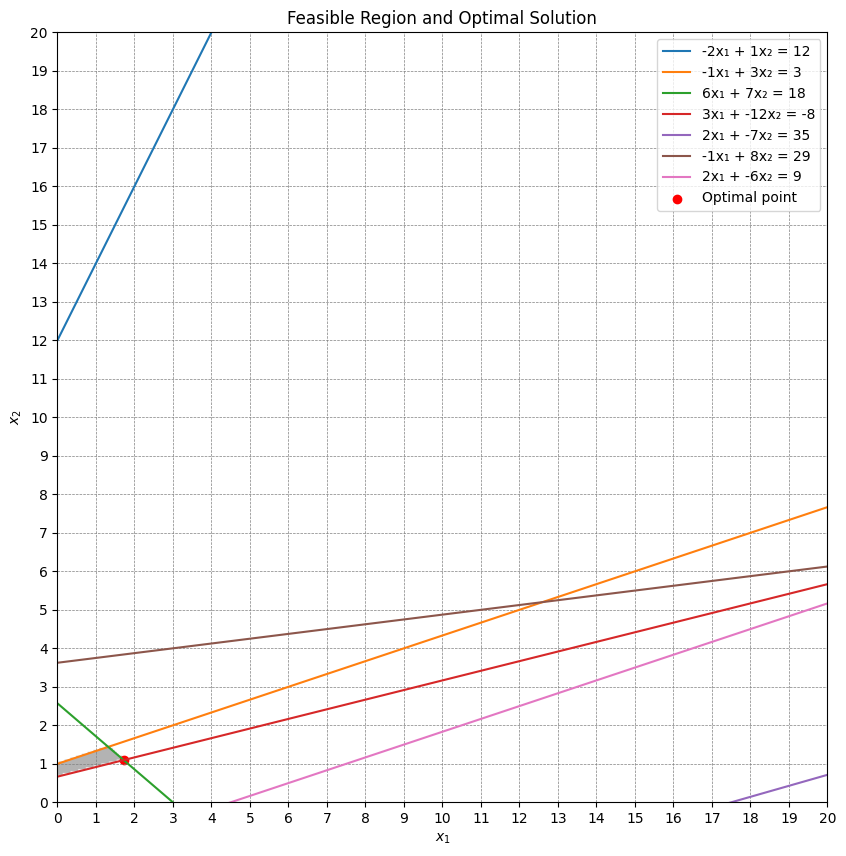

In [4]:
x1_vals = np.linspace(0, 20, 400)

# helper function to plot each line
def line(a, b, c, x):
    return (c - a * x) / b

# all constraints
lines = [
    (-2, 1, 12),
    (-1, 3, 3),
    (6, 7, 18),
    (3, -12, -8),
    (2, -7, 35),
    (-1, 8, 29),
    (2, -6, 9)
]

# plot each line
plt.figure(figsize=(10, 10))
for a, b, c_ in lines:
    plt.plot(x1_vals, line(a, b, c_, x1_vals), label=f"{a}x₁ + {b}x₂ = {c_}")

# feasible region shading
X, Y = np.meshgrid(np.linspace(0, 20, 400), np.linspace(0, 20, 400))
Z = np.ones_like(X, dtype=bool)
for (a, b, c_) in lines:
    Z &= a * X + b * Y <= c_

plt.imshow(Z[::-1], extent=(0, 20, 0, 20), alpha=0.3, cmap='bone_r')

# plot optimal point
if res.success:
    plt.scatter(res.x[0], res.x[1], color='red', label='Optimal point')

plt.xlim(0, 20)
plt.ylim(0, 20)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('Feasible Region and Optimal Solution')
plt.legend()

# grid every 1 unit
plt.xticks(np.arange(0, 21, 1))
plt.yticks(np.arange(0, 21, 1))
plt.grid(True, which='both', color='gray', linestyle='--', linewidth=0.5)

plt.show()


### 3. Ερμηνεία αποτελεσμάτων

Το πρόβλημα είναι η μεγιστοποίηση της $z = 3x_1 - 10x_2$ υπό επτά γραμμικούς περιορισμούς και τους περιορισμούς $x_1, x_2 \ge 0$. Η `linprog` της SciPy βρίσκει το σημείο $(x_1, x_2)$ που ικανοποιεί όλους τους περιορισμούς και μεγιστοποιεί τη $z$. Η βέλτιστη λύση είναι $(x_1, x_2) \approx (1{,}72,\ 1{,}10)$ με $z \approx -5{,}81$. Η τιμή είναι αρνητική, αλλά είναι το μέγιστο της $z$ στην εφικτή περιοχή.

Η γκρι περιοχή του γραφήματος αναπαριστά την **εφικτή περιοχή**, δηλαδή την τομή των ημιεπιπέδων που ορίζουν οι περιορισμοί, και το κόκκινο σημείο είναι η **βέλτιστη λύση**. Όπως αναμένεται, η λύση βρίσκεται σε κορυφή της εφικτής περιοχής, και συγκεκριμένα στην τομή των ευθειών $6x_1 + 7x_2 = 18$ και $3x_1 - 12x_2 = -8$. Η επίλυση του συστήματος δίνει $x_1 = 160/93$ και $x_2 = 34/31$, άρα $z = -180/31$, που συμφωνεί με το αποτέλεσμα της `linprog`.

Οι περιορισμοί που ήταν αρχικά ανισότητες της μορφής «≥» πολλαπλασιάστηκαν με −1, για να έρθουν στη μορφή «≤» που απαιτεί η `linprog`. Η αλλαγή αυτή δεν επηρεάζει τη λύση, αφού το πρόβλημα παραμένει μαθηματικά ισοδύναμο με το αρχικό.